# Tarea 1 — Extracción de descriptores de patrones en imágenes
**Reconocimiento de Patrones en Imágenes — Laura Romero**

**Supuestos y decisiones de diseño:**
- Se detectó que las 36 letras de la imagen están completamente separadas entre sí (ninguna se toca ni se superpone), por lo que la segmentación se hace con componentes conexas (`cv2.connectedComponents`) sin necesidad de técnicas adicionales de separación (watershed, etc.).
- Los momentos de Hu se reportan en escala logarítmica (`-sign(h)*log10(|h|)`), estándar en la literatura, ya que los valores crudos tienen órdenes de magnitud muy distintos entre sí.
- La redondez se calcula con la fórmula clásica de circularidad `R = 4·pi·Área / Perímetro²` (R=1 para un círculo perfecto).
- El ángulo de la elipse se obtiene con el **método de Fitzgibbon (1996)** visto en clases (mismas funciones `fitzgibbon`/`parametros` del material de clase), aplicado sobre las coordenadas del contorno externo de cada letra, centradas en su propio origen para evitar inestabilidad numérica del ajuste (las coordenadas de píxeles sin centrar generan un mal condicionamiento en el problema de eigenvalores generalizado).

In [2]:
# Uso: dejar este notebook junto a 'sopa_letras.png' y ejecutar todas las celdas en orden (Run All).
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IMG_PATH = 'sopa_letras.png'

In [3]:
# --- Método de Fitzgibbon (1996) para ajuste de elipse ---
# (misma formulación que el material de clase: min ||X*a|| sujeto a a^T C a = 1)

def fitzgibbon(x, y):
    n = x.shape[0]
    D = [x**2, x*y, y**2, x, y, np.ones((n, 1))]
    D = np.hstack(D)
    S = np.matmul(D.T, D)                 # matriz de dispersión
    C = np.zeros((6, 6))
    C[0, 2] = 2; C[1, 1] = -1; C[2, 0] = 2  # matriz de restricción

    E, V = np.linalg.eig(np.dot(np.linalg.inv(S), C))
    # nota: si las coordenadas no están centradas, eig puede devolver
    # una parte imaginaria espuria de orden 1e-10 por mal condicionamiento
    # numérico; se descarta ya que el problema es real por construcción.
    E = np.real(E); V = np.real(V)

    idx = np.argwhere((E > 0) & (~np.isinf(E)))
    if len(idx) == 0:
        idx = np.argwhere(~np.isinf(E))[:1]
    params = V[:, idx[0]]
    return params.ravel()


def parametros(x, y):
    a, b, c, d, e, f = fitzgibbon(x, y)
    alpha = np.arctan2(b, a - c) / 2

    ct, st = np.cos(alpha), np.sin(alpha)
    ap = a*ct*ct + b*ct*st + c*st*st
    cp = a*st*st - b*ct*st + c*ct*ct

    T = np.array([[a, b/2], [b/2, c]])
    t = -1 * np.matmul(np.linalg.inv(2*T), np.array([d, e]).reshape(2, 1))

    val = np.matmul(t.T, np.matmul(T, t))
    scale = 1 / (val - f)

    r1 = 1 / np.sqrt(scale * ap)
    r2 = 1 / np.sqrt(scale * cp)

    return r1.item(), r2.item(), t[0].item(), t[1].item(), alpha

In [4]:
# --- Segmentación: cada letra es una componente conexa independiente ---
img_color = cv2.imread(IMG_PATH)
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Otsu invertido: letras oscuras sobre fondo claro -> foreground = 255
_, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(bw, connectivity=8)

AREA_MIN = 20  # descarta ruido/artefactos de antialiasing

filas = []
centros = []

for i in range(1, n_labels):
    if stats[i, cv2.CC_STAT_AREA] < AREA_MIN:
        continue

    mask = np.uint8(labels == i)

    # contorno externo de la letra (para perímetro y elipse)
    contornos, _ = cv2.findContours(np.uint8(mask*255), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contorno = max(contornos, key=cv2.contourArea)

    # --- (1) Momentos de Hu (sobre la máscara, para incluir huecos internos ej. 'a','b','g') ---
    m = cv2.moments(mask, binaryImage=True)
    hu = cv2.HuMoments(m).flatten()
    hu_log = -np.sign(hu) * np.log10(np.abs(hu))  # escala logarítmica estándar

    # --- (2) Perímetro ---
    perimetro = cv2.arcLength(contorno, True)

    # --- (3) Redondez: 4*pi*Area/Perimetro^2  (1.0 = círculo perfecto) ---
    area = m['m00']
    redondez = 4 * np.pi * area / (perimetro ** 2)

    # centro de masa (para la imagen final)
    cx, cy = m['m10'] / m['m00'], m['m01'] / m['m00']
    centros.append((cx, cy))

    # --- (4) Ángulo de la elipse: método de Fitzgibbon sobre el contorno ---
    pts = contorno.reshape(-1, 2).astype(float)
    x = pts[:, 0].reshape(-1, 1)
    y = pts[:, 1].reshape(-1, 1)
    x0, y0 = x.mean(), y.mean()  # se centra para estabilidad numérica del ajuste
    _, _, _, _, alpha = parametros(x - x0, y - y0)
    angulo_deg = np.degrees(alpha)

    filas.append({
        'ID': len(filas) + 1,
        'Hu1': hu_log[0], 'Hu2': hu_log[1], 'Hu3': hu_log[2], 'Hu4': hu_log[3],
        'Perimetro': round(perimetro, 2),
        'Redondez': round(redondez, 4),
        'Angulo_Elipse_deg': round(angulo_deg, 2),
    })

df = pd.DataFrame(filas)
print(f'Letras detectadas: {len(df)}')

Letras detectadas: 36


In [5]:
# --- Resultado 1: DataFrame con los descriptores ---
df

,ID,Hu1,Hu2,Hu3,Hu4,Perimetro,Redondez,Angulo_Elipse_deg
0,1,0.371225,1.586559,1.857879,3.135372,226.35,0.2973,-41.86
1,2,0.472206,2.407093,3.040407,3.389876,206.71,0.2859,84.26
2,3,0.439795,1.926086,2.661389,3.347413,251.71,0.2606,42.70
3,4,0.588410,2.780459,3.559487,3.794333,129.20,0.3516,54.69
4,5,0.438636,1.492712,2.952065,3.794001,188.71,0.2618,4.78
5,6,0.534471,1.986342,2.598917,3.069527,67.11,0.3655,0.00
6,7,0.272465,0.670930,1.598230,2.091784,215.18,0.2030,38.99
7,8,0.450886,1.972225,2.666442,3.257356,150.33,0.2708,11.69
8,9,0.271500,0.670138,1.586150,2.069384,153.58,0.2040,39.12
9,10,0.533334,1.909257,2.308902,3.474277,88.91,0.4499,44.94


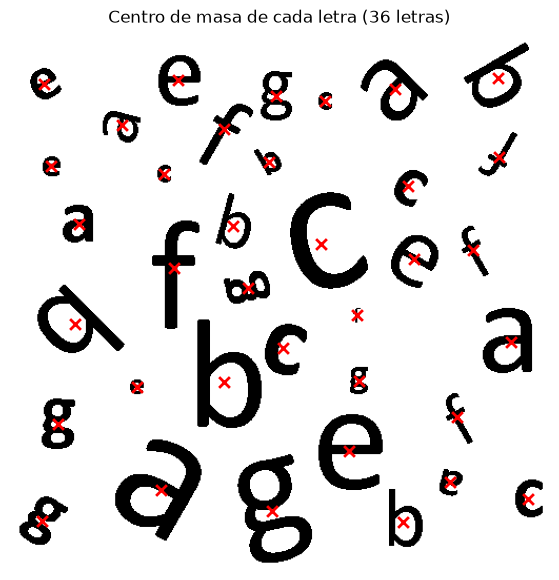

In [6]:
# --- Resultado 2: centro de masa de cada letra sobre la imagen original ---
plt.figure(figsize=(7, 7))
plt.imshow(img_rgb)
xs = [c[0] for c in centros]
ys = [c[1] for c in centros]
plt.scatter(xs, ys, c='red', marker='x', s=60, linewidths=2)
plt.title(f'Centro de masa de cada letra ({len(centros)} letras)')
plt.axis('off')
plt.show()